# US Tennis Courts Data Analysis & Visualization

## 1) Import Libraries and Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

df = pd.read_csv("tennis_courts.csv")
print("Shape:", df.shape)
df.head()

Shape: (29959, 16)


,index,name,address,city,state,zip_code,type,count,clay,wall,grass,indoor,lights,proshop,latitude,longitude
0,0,Adelphi Road,washington,dc,20782.0,Public,6,False,True,False,False,False,False,38.974351,-76.952112,"{""clay""=>""0"", ""type""=>""Public"", ""wall""=>""1"", ""..."
1,1,Brandywood Circle,orlando,fl,32792.0,Homeowners Community,1,False,False,False,False,True,False,28.590956,-81.285224,"{""clay""=>""0"", ""type""=>""Homeowners Community"", ..."
2,2,Greenlee Drive,austin-san marcos,tx,78628.0,Public,8,False,True,False,False,True,False,30.615173,-97.700794,"{""clay""=>""0"", ""type""=>""Public"", ""wall""=>""1"", ""..."
3,3,McKee Street,minneapolis-st. paul,mn,55121.0,Public,1,False,False,False,False,False,False,44.852096,-93.142100,"{""clay""=>""0"", ""type""=>""Public"", ""wall""=>""0"", ""..."
4,4,Avenue North,minneapolis-st. paul,mn,55374.0,Public,6,False,False,False,False,False,False,45.207841,-93.544174,"{""clay""=>""0"", ""type""=>""Public"", ""wall""=>""0"", ""..."


## 2) Initial Inspection

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29959 entries, 0 to 29958
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   index      29959 non-null  int64  
 1   name       29959 non-null  str    
 2   address    29959 non-null  str    
 3   city       29959 non-null  str    
 4   state      29958 non-null  float64
 5   zip_code   29959 non-null  str    
 6   type       29959 non-null  int64  
 7   count      29959 non-null  bool   
 8   clay       29959 non-null  bool   
 9   wall       29959 non-null  bool   
 10  grass      29959 non-null  bool   
 11  indoor     29959 non-null  bool   
 12  lights     29959 non-null  bool   
 13  proshop    29959 non-null  float64
 14  latitude   29959 non-null  float64
 15  longitude  29959 non-null  str    
dtypes: bool(6), float64(3), int64(2), str(5)
memory usage: 2.5 MB


**Problem found:** the column names do not match the data. Every name is shifted by one position
(for example `city` holds state codes, `state` holds ZIP codes, and `longitude` holds a JSON-like text blob).

| Header says | What the column really contains |
|---|---|
| `address` | metro area |
| `city` | state code |
| `state` | ZIP code |
| `zip_code` | ownership type (Public / Homeowners Community) |
| `type` | number of courts |
| `count`, `clay`, `wall`, `grass`, `indoor`, `lights` | clay, wall, grass, indoor, lights, pro shop (True/False) |
| `proshop` | latitude |
| `latitude` | longitude |
| `longitude` | attribute blob (the original values as text) |

In [3]:
# Rename the columns by position
df.columns = ["index", "facility_name", "metro_area", "state", "zip_code", "ownership_type",
              "num_courts", "clay", "wall", "grass", "indoor", "lights", "proshop",
              "latitude", "longitude", "attributes_raw"]
df.head(3)

,index,facility_name,metro_area,state,zip_code,ownership_type,num_courts,clay,wall,grass,indoor,lights,proshop,latitude,longitude,attributes_raw
0,0,Adelphi Road,washington,dc,20782.0,Public,6,False,True,False,False,False,False,38.974351,-76.952112,"{""clay""=>""0"", ""type""=>""Public"", ""wall""=>""1"", ""..."
1,1,Brandywood Circle,orlando,fl,32792.0,Homeowners Community,1,False,False,False,False,True,False,28.590956,-81.285224,"{""clay""=>""0"", ""type""=>""Homeowners Community"", ..."
2,2,Greenlee Drive,austin-san marcos,tx,78628.0,Public,8,False,True,False,False,True,False,30.615173,-97.700794,"{""clay""=>""0"", ""type""=>""Public"", ""wall""=>""1"", ""..."


In [4]:
# Verify the new names: every row also stores its original values inside the blob
check = {}
for c in ["clay", "wall", "grass", "indoor", "lights", "proshop"]:
    check[c] = (df[c] == df["attributes_raw"].str.contains(f'"{c}"=>"1"')).mean()
check["ownership_type"] = (df["ownership_type"] == df["attributes_raw"].str.extract(r'"type"=>"([^"]*)"', expand=False)).mean()
blob_courts = df["attributes_raw"].str.extract(r'"count"=>"(\d+)"', expand=False).astype(float)
check["num_courts"] = (df["num_courts"] == blob_courts).mean()

pd.Series(check).map("{:.3%}".format).to_frame("match with blob")

,match with blob
clay,100.000%
wall,100.000%
grass,100.000%
indoor,100.000%
lights,100.000%
proshop,100.000%
ownership_type,100.000%
num_courts,99.997%


In [5]:
# The one court-count mismatch: the original value is null (stored as 0 in the CSV)
df[df["num_courts"] != blob_courts][["facility_name", "metro_area", "state", "num_courts"]]

,facility_name,metro_area,state,num_courts
13908,Crescent Street,washington,dc,0


In [6]:
# Count and percentage of missing values
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
missing[missing.missing_count > 0]

,missing_count,missing_%
zip_code,1,0.0


## 3) Data Cleaning

In [7]:
df_clean = df.copy()

# --- Text and ZIP code ---
df_clean["facility_name"] = df_clean["facility_name"].str.strip()
df_clean["state"] = df_clean["state"].str.upper()
df_clean["metro_area"] = df_clean["metro_area"].str.title()
# ZIP codes were stored as decimals (20782.0): convert to 5-digit text, keep leading zeros
df_clean["zip_code"] = df_clean["zip_code"].astype("Int64").astype("string").str.zfill(5).fillna("Unknown")

# --- Hidden attributes that only exist inside the blob ---
df_clean["stringing"] = df_clean["attributes_raw"].str.contains('"stringing"=>"1"')
df_clean["quality"] = df_clean["attributes_raw"].str.extract(r'"quality"=>"([^"]*)"', expand=False)
df_clean["IsRated"] = df_clean["quality"].notnull().astype(int)
df_clean["quality"] = df_clean["quality"].fillna("Not rated")
df_clean = df_clean.drop(columns="attributes_raw")

# --- Duplicates (same facility, different row id) ---
cols_wo_id = [c for c in df_clean.columns if c != "index"]
dups = df_clean.duplicated(subset=cols_wo_id).sum()
print("Duplicate rows:", dups)
df_clean = df_clean.drop_duplicates(subset=cols_wo_id)

# --- Invalid rows: a facility must have at least 1 court ---
zero = (df_clean["num_courts"] == 0).sum()
print("Facilities with 0 courts:", zero)
df_clean = df_clean[df_clean["num_courts"] > 0]

df_clean = df_clean.drop(columns="index").reset_index(drop=True)

print("Remaining missing values:\n", df_clean.isnull().sum()[lambda s: s > 0])
print("Shape after cleaning:", df_clean.shape)

Duplicate rows: 4


Facilities with 0 courts: 1
Remaining missing values:
 Series([], dtype: int64)
Shape after cleaning: (29954, 17)


## 4) Feature Engineering

In [8]:
feature_cols = ["clay", "wall", "grass", "indoor", "lights", "proshop", "stringing"]

df_clean["IsPublic"] = (df_clean["ownership_type"] == "Public").astype(int)
df_clean["FeatureCount"] = df_clean[feature_cols].sum(axis=1)
df_clean["HasAnyFeature"] = (df_clean["FeatureCount"] > 0).astype(int)
df_clean["IsLarge"] = (df_clean["num_courts"] >= 5).astype(int)

df_clean["SizeGroup"] = pd.cut(df_clean["num_courts"], bins=[0, 1, 2, 4, 8, np.inf],
                               labels=["1", "2", "3-4", "5-8", "9+"])
df_clean[["facility_name", "num_courts", "SizeGroup", "IsLarge", "IsPublic", "FeatureCount"]].head()

,facility_name,num_courts,SizeGroup,IsLarge,IsPublic,FeatureCount
0,Adelphi Road,6,5-8,1,1,1
1,Brandywood Circle,1,1,0,0,1
2,Greenlee Drive,8,5-8,1,1,2
3,McKee Street,1,1,0,1,0
4,Avenue North,6,5-8,1,1,0


## 5) Descriptive Statistics

In [9]:
df_clean[["num_courts", "FeatureCount", "latitude", "longitude"]].describe().round(2)

,num_courts,FeatureCount,latitude,longitude
count,29954.0,29954.00,29954.00,29954.00
mean,3.0,0.65,36.74,-90.21
std,2.5,0.67,5.36,15.80
min,1.0,0.00,25.45,-123.39
25%,2.0,0.00,33.52,-97.08
50%,2.0,1.00,37.78,-84.29
75%,4.0,1.00,40.90,-78.96
max,41.0,6.00,48.30,-70.38


In [10]:
# Extra statistics: skewness, kurtosis, median, mode
num = df_clean[["num_courts", "FeatureCount"]]
pd.DataFrame({
    "mean": num.mean(), "median": num.median(),
    "mode": num.mode().iloc[0], "std": num.std(),
    "skew": num.skew(), "kurtosis": num.kurt()
}).round(2)

,mean,median,mode,std,skew,kurtosis
num_courts,3.00,2.0,2,2.50,2.84,15.26
FeatureCount,0.65,1.0,1,0.67,0.87,1.37


In [11]:
# Categorical columns
for col in ["ownership_type", "SizeGroup", "quality"]:
    print(f"--- {col} ---")
    print(df_clean[col].value_counts().to_string(), "\n")

print("--- Top 10 states ---")
print(df_clean["state"].value_counts().head(10).to_string(), "\n")
print("--- Top 10 metro areas ---")
print(df_clean["metro_area"].value_counts().head(10).to_string())

--- ownership_type ---
ownership_type
Public                  16222
Homeowners Community    13732 

--- SizeGroup ---
SizeGroup
2      12264
1       7030
3-4     5561
5-8     4205
9+       894 

--- quality ---
quality
Not rated    29669
Excellent      107
Good            79
Fair            47
Poor            26
Unusable        26 

--- Top 10 states ---
state
CA    3864
FL    3811
NY    3164
TX    2619
GA    2303
IL    1386
OH    1175
NC    1081
MA    1052
PA    1021 

--- Top 10 metro areas ---
metro_area
New York                              2663
Atlanta                               2303
Los Angeles                           1879
Chicago                               1386
Miami-Fort Lauderdale                 1162
Boston                                1052
Houston - Galveston - Brazoria        1049
San Francisco - Oakland - San Jose     973
Dallas - Fort Worth                    952
Minneapolis-St. Paul                   805


## 6) EDA Summary

In [12]:
overall = df_clean["IsPublic"].mean()
print(f"Overall public share of facilities: {overall:.1%}")
print(f"Public share of all courts: {df_clean.loc[df_clean.IsPublic == 1, 'num_courts'].sum() / df_clean['num_courts'].sum():.1%}\n")

for col in ["ownership_type", "SizeGroup"]:
    t = (df_clean.groupby(col, observed=True)
         .agg(facilities=("num_courts", "count"), total_courts=("num_courts", "sum"),
              avg_courts=("num_courts", "mean"), lights=("lights", "mean"), wall=("wall", "mean"),
              clay=("clay", "mean"), proshop=("proshop", "mean"), indoor=("indoor", "mean")).round(3))
    print(f"Profile by {col}")
    print(t.to_string(), "\n")

Overall public share of facilities: 54.2%
Public share of all courts: 72.0%

Profile by ownership_type
                      facilities  total_courts  avg_courts  lights   wall   clay  proshop  indoor
ownership_type                                                                                   
Homeowners Community       13732         25206       1.836   0.559  0.068  0.020    0.002   0.000
Public                     16222         64757       3.992   0.374  0.236  0.012    0.008   0.005 

Profile by SizeGroup
           facilities  total_courts  avg_courts  lights   wall   clay  proshop  indoor
SizeGroup                                                                             
1                7030          7030       1.000   0.435  0.050  0.009    0.000   0.001
2               12264         24528       2.000   0.478  0.131  0.010    0.000   0.000
3-4              5561         20340       3.658   0.455  0.224  0.015    0.001   0.003
5-8              4205         27259       6.483

In [13]:
# Top 12 states: size, ownership and features
state_tbl = (df_clean.groupby("state")
             .agg(facilities=("num_courts", "count"), total_courts=("num_courts", "sum"),
                  avg_courts=("num_courts", "mean"), public_share=("IsPublic", "mean"),
                  lights=("lights", "mean"), wall=("wall", "mean"), clay=("clay", "mean"))
             .sort_values("facilities", ascending=False).round(3))
state_tbl.head(12)

,facilities,total_courts,avg_courts,public_share,lights,wall,clay
state,,,,,,,
CA,3864,12898,3.338,0.540,0.561,0.165,0.002
FL,3811,9411,2.469,0.245,0.603,0.105,0.056
NY,3164,10374,3.279,0.663,0.205,0.149,0.042
TX,2619,7901,3.017,0.513,0.691,0.263,0.008
GA,2303,5913,2.568,0.182,0.722,0.069,0.006
IL,1386,4595,3.315,0.812,0.263,0.167,0.006
OH,1175,3517,2.993,0.622,0.339,0.157,0.005
NC,1081,3128,2.894,0.384,0.585,0.126,0.009
MA,1052,2950,2.804,0.644,0.286,0.142,0.009


In [14]:
# Pivot table: share of facilities with lights, by size group x ownership
pd.pivot_table(df_clean, values="lights", index="SizeGroup", columns="ownership_type",
               aggfunc="mean", observed=True).round(3)

ownership_type,Homeowners Community,Public
SizeGroup,,
1,0.488,0.237
2,0.575,0.359
3-4,0.723,0.387
5-8,0.869,0.388
9+,0.882,0.584


In [15]:
# Average courts and feature count by ownership
df_clean.groupby("ownership_type")[["num_courts", "FeatureCount"]].mean().round(2)

,num_courts,FeatureCount
ownership_type,,
Homeowners Community,1.84,0.65
Public,3.99,0.64


## 7) Correlation Analysis

In [16]:
corr_cols = ["num_courts", "IsPublic", "lights", "wall", "clay", "proshop", "stringing", "indoor", "grass", "FeatureCount"]
corr = df_clean[corr_cols].astype(float).corr().round(2)
corr

,num_courts,IsPublic,lights,wall,clay,proshop,stringing,indoor,grass,FeatureCount
num_courts,1.00,0.43,0.03,0.22,0.13,0.29,0.24,0.13,0.03,0.23
IsPublic,0.43,1.00,-0.19,0.23,-0.03,0.04,0.05,0.04,0.01,-0.01
lights,0.03,-0.19,1.00,0.03,0.02,0.07,0.05,-0.00,0.01,0.78
wall,0.22,0.23,0.03,1.00,0.00,0.04,0.03,0.01,-0.01,0.57
clay,0.13,-0.03,0.02,0.00,1.00,0.19,0.11,0.04,0.03,0.24
proshop,0.29,0.04,0.07,0.04,0.19,1.00,0.67,0.14,0.02,0.29
stringing,0.24,0.05,0.05,0.03,0.11,0.67,1.00,0.18,0.03,0.26
indoor,0.13,0.04,-0.00,0.01,0.04,0.14,0.18,1.00,0.03,0.12
grass,0.03,0.01,0.01,-0.01,0.03,0.02,0.03,0.03,1.00,0.04
FeatureCount,0.23,-0.01,0.78,0.57,0.24,0.29,0.26,0.12,0.04,1.00


In [17]:
# Strongest correlations with the number of courts
corr["num_courts"].drop("num_courts").sort_values(key=abs, ascending=False)

IsPublic        0.43
proshop         0.29
stringing       0.24
FeatureCount    0.23
wall            0.22
indoor          0.13
clay            0.13
lights          0.03
grass           0.03
Name: num_courts, dtype: float64

## 8) Visualizations

### Viz 1 — Facilities by Ownership Type

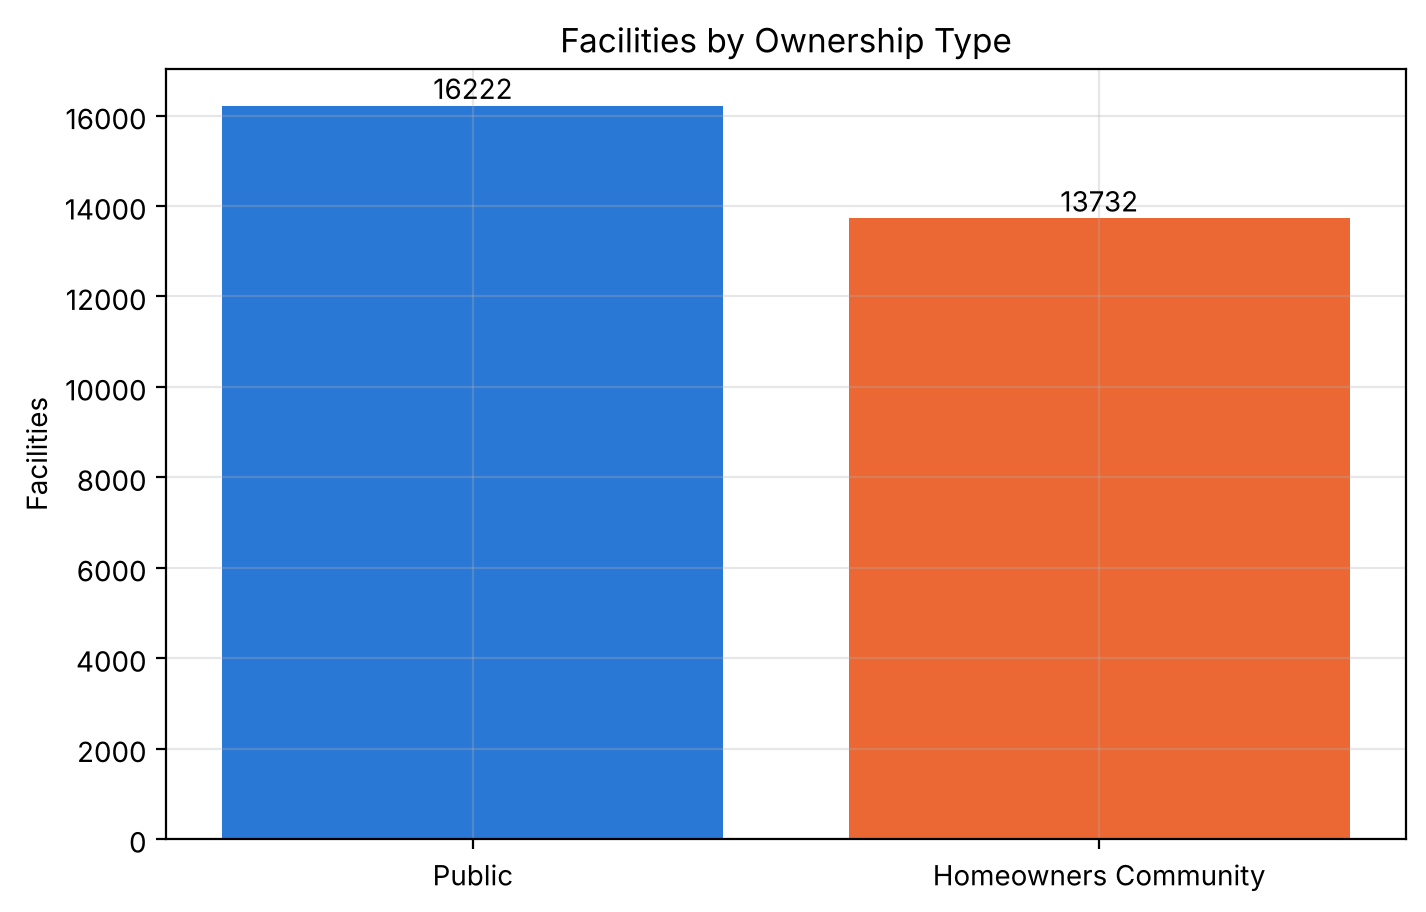

In [18]:
counts = df_clean["ownership_type"].value_counts()
fig, ax = plt.subplots()
bars = ax.bar(counts.index, counts.values, color=["#2a78d6", "#eb6834"])
ax.bar_label(bars)
ax.set_title("Facilities by Ownership Type")
ax.set_ylabel("Facilities")
plt.show()

### Viz 2 — Distribution of Courts per Facility

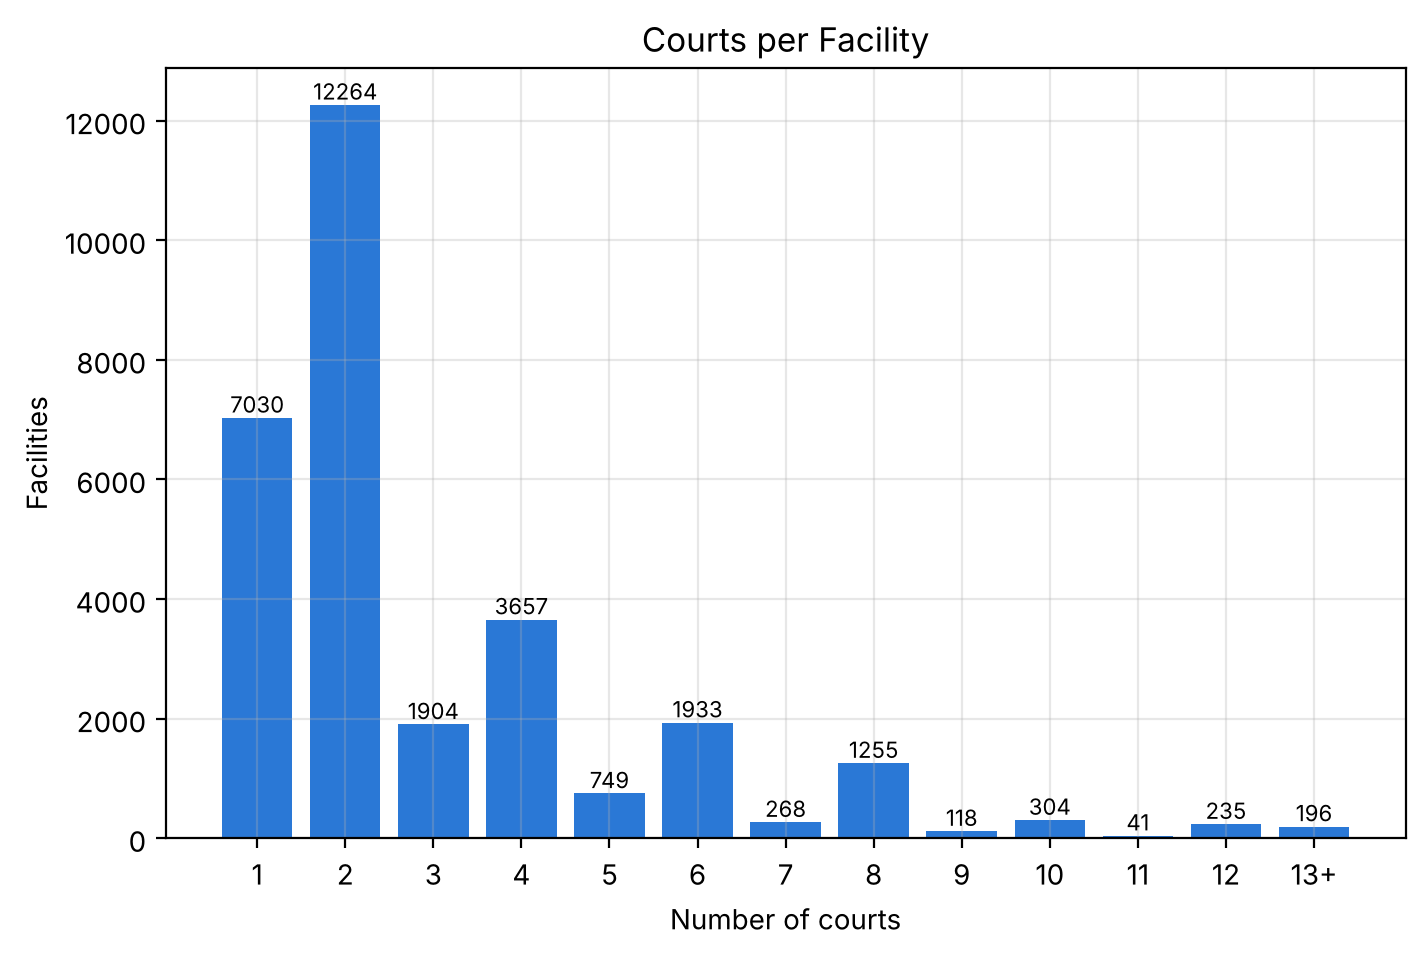

In [19]:
dist = df_clean["num_courts"].clip(upper=13).value_counts().sort_index()
labels = [str(i) if i < 13 else "13+" for i in dist.index]
fig, ax = plt.subplots()
bars = ax.bar(labels, dist.values, color="#2a78d6")
ax.bar_label(bars, fontsize=8)
ax.set_title("Courts per Facility")
ax.set_xlabel("Number of courts")
ax.set_ylabel("Facilities")
plt.show()

### Viz 3 — Feature Availability by Ownership Type

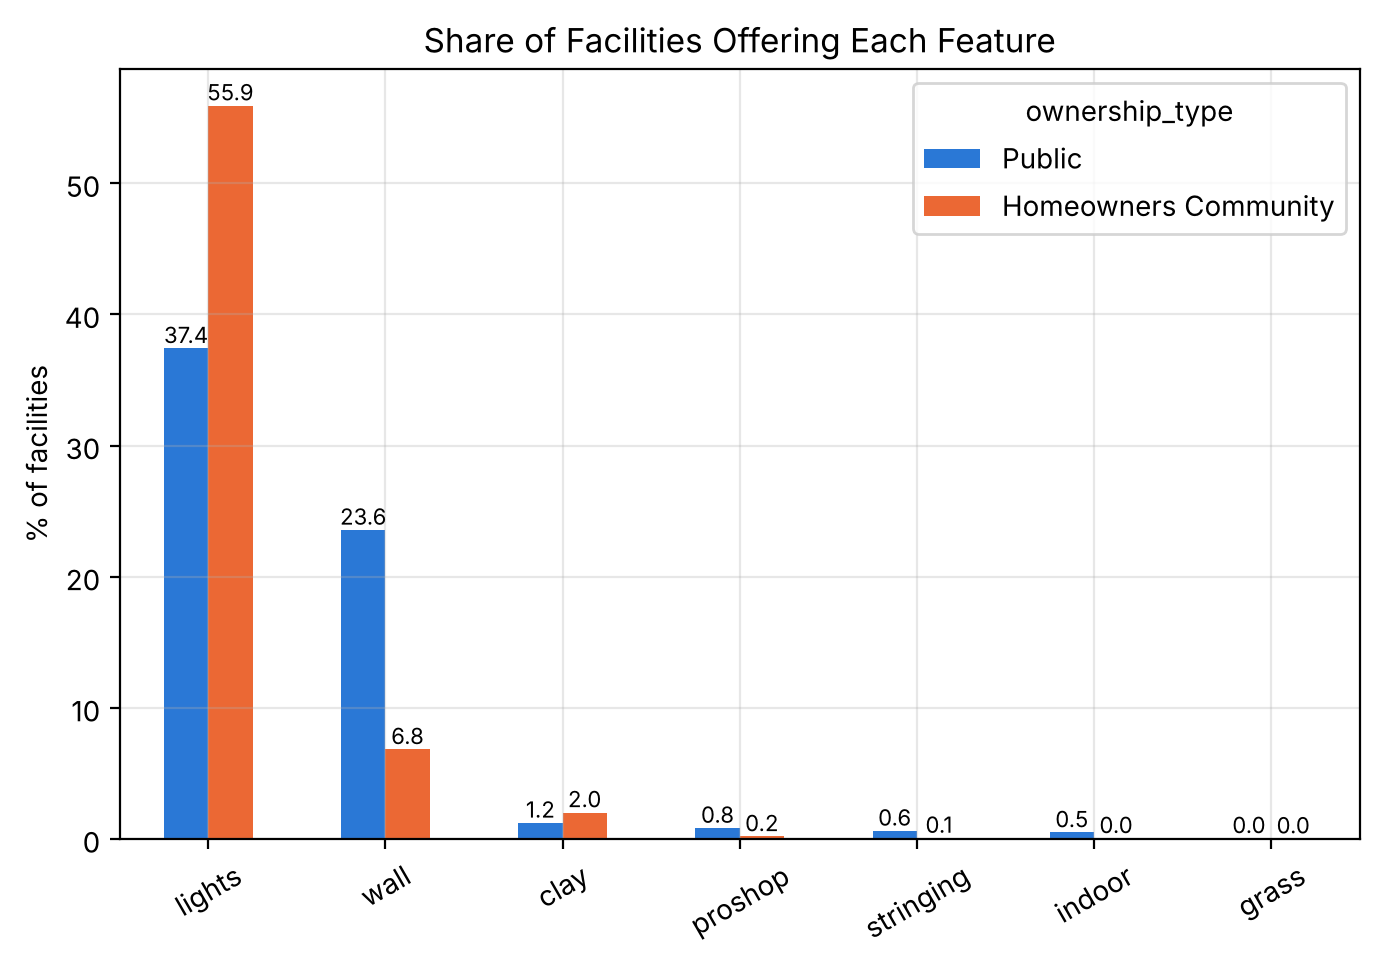

In [20]:
rates = df_clean.groupby("ownership_type")[["lights", "wall", "clay", "proshop", "stringing", "indoor", "grass"]].mean().T * 100
ax = rates[["Public", "Homeowners Community"]].plot(kind="bar", color=["#2a78d6", "#eb6834"], rot=30)
ax.set_title("Share of Facilities Offering Each Feature")
ax.set_ylabel("% of facilities")
ax.set_xlabel("")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.show()

### Viz 4 — Courts per Facility by Ownership (Boxplot, shows outliers)

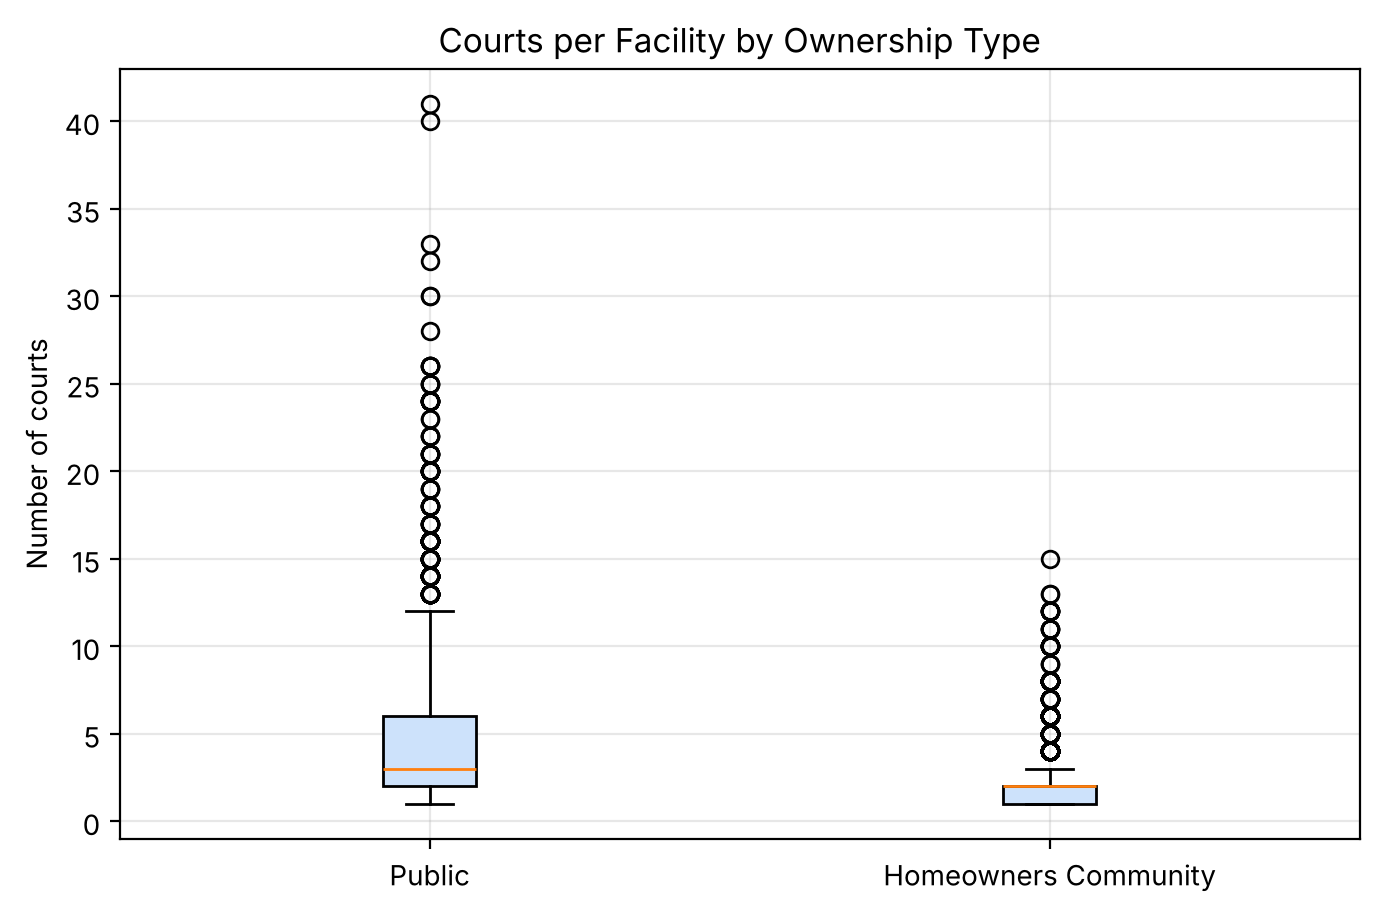

In [21]:
groups = [df_clean.loc[df_clean.ownership_type == o, "num_courts"] for o in ["Public", "Homeowners Community"]]
fig, ax = plt.subplots()
ax.boxplot(groups, patch_artist=True, boxprops=dict(facecolor="#cde2fb"))
ax.set_xticks([1, 2])
ax.set_xticklabels(["Public", "Homeowners Community"])
ax.set_title("Courts per Facility by Ownership Type")
ax.set_ylabel("Number of courts")
plt.show()

### Viz 5 — Top 15 States by Number of Facilities

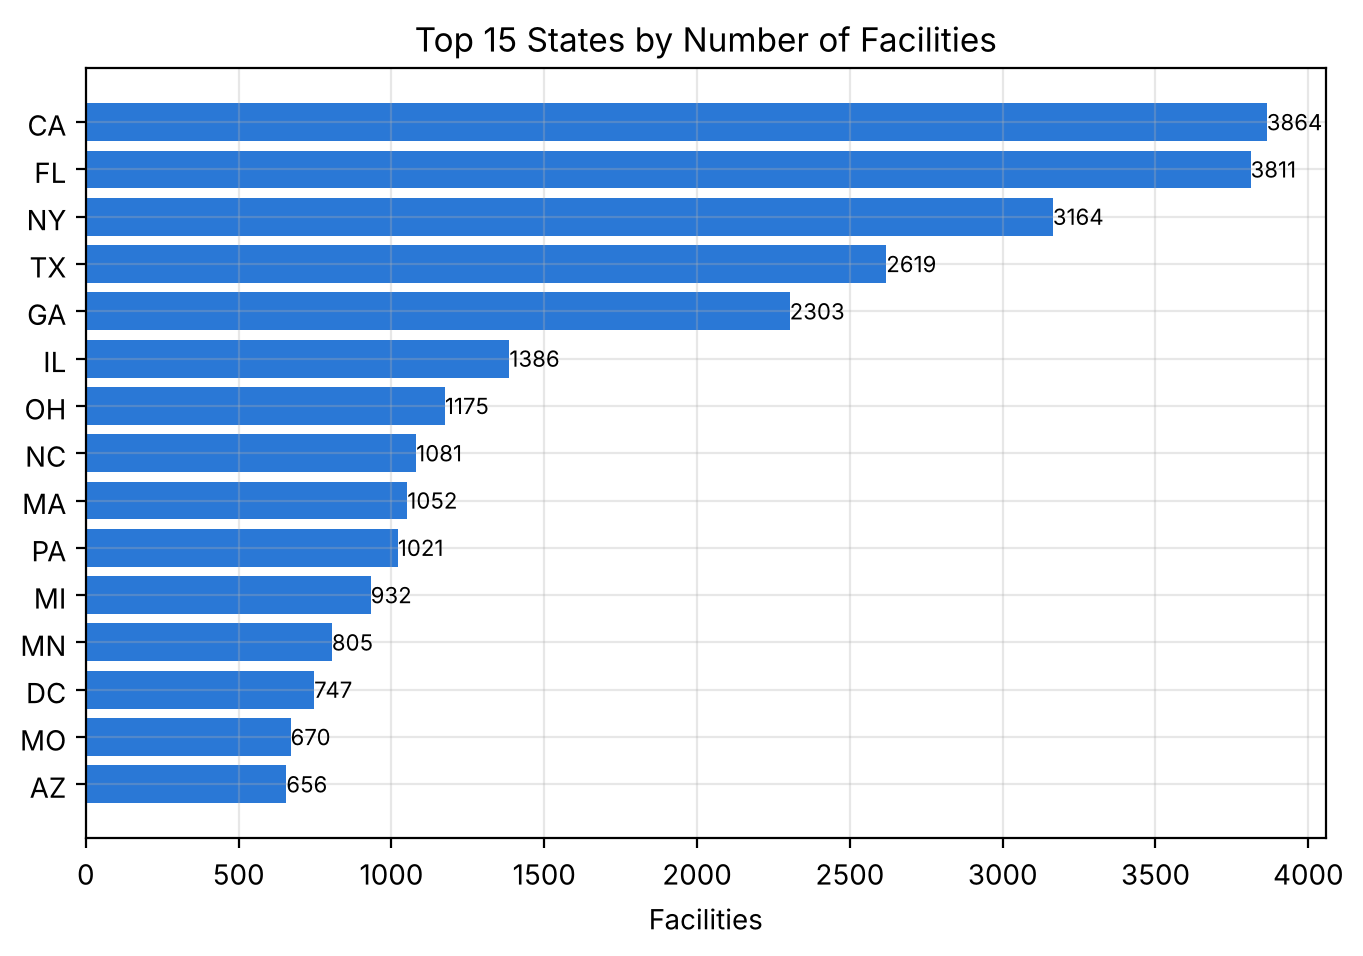

In [22]:
top = df_clean["state"].value_counts().head(15).sort_values()
fig, ax = plt.subplots()
bars = ax.barh(top.index, top.values, color="#2a78d6")
ax.bar_label(bars, fontsize=8)
ax.set_title("Top 15 States by Number of Facilities")
ax.set_xlabel("Facilities")
plt.show()

### Viz 6 — Public Share of Facilities (Top 15 States)

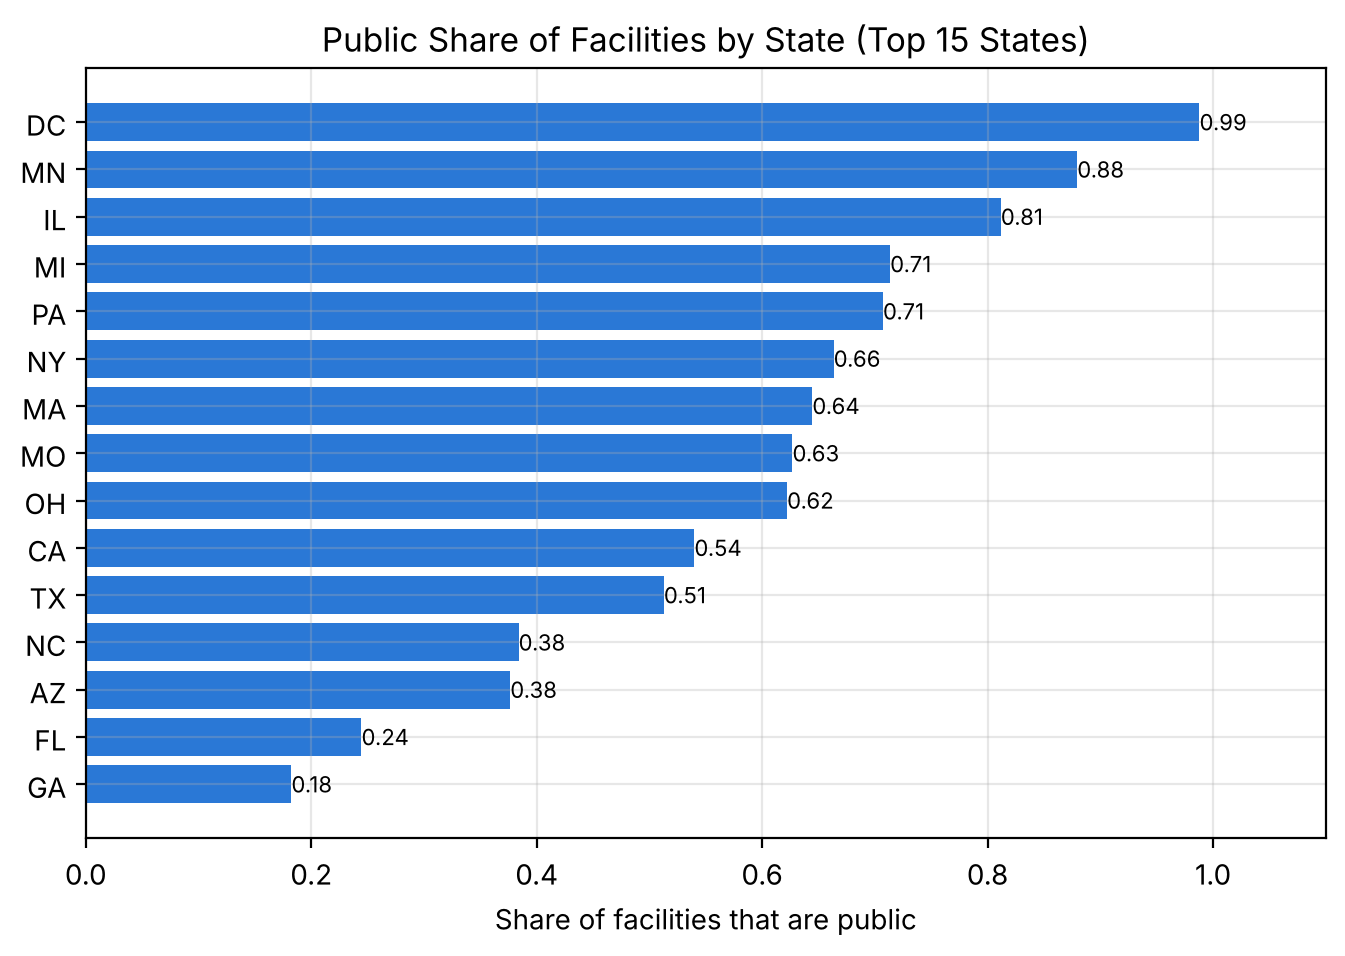

In [23]:
top_states = df_clean["state"].value_counts().head(15).index
share = df_clean[df_clean["state"].isin(top_states)].groupby("state")["IsPublic"].mean().sort_values()
fig, ax = plt.subplots()
bars = ax.barh(share.index, share.values, color="#2a78d6")
ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_title("Public Share of Facilities by State (Top 15 States)")
ax.set_xlabel("Share of facilities that are public")
ax.set_xlim(0, 1.1)
plt.show()

### Viz 7 — Correlation Heatmap

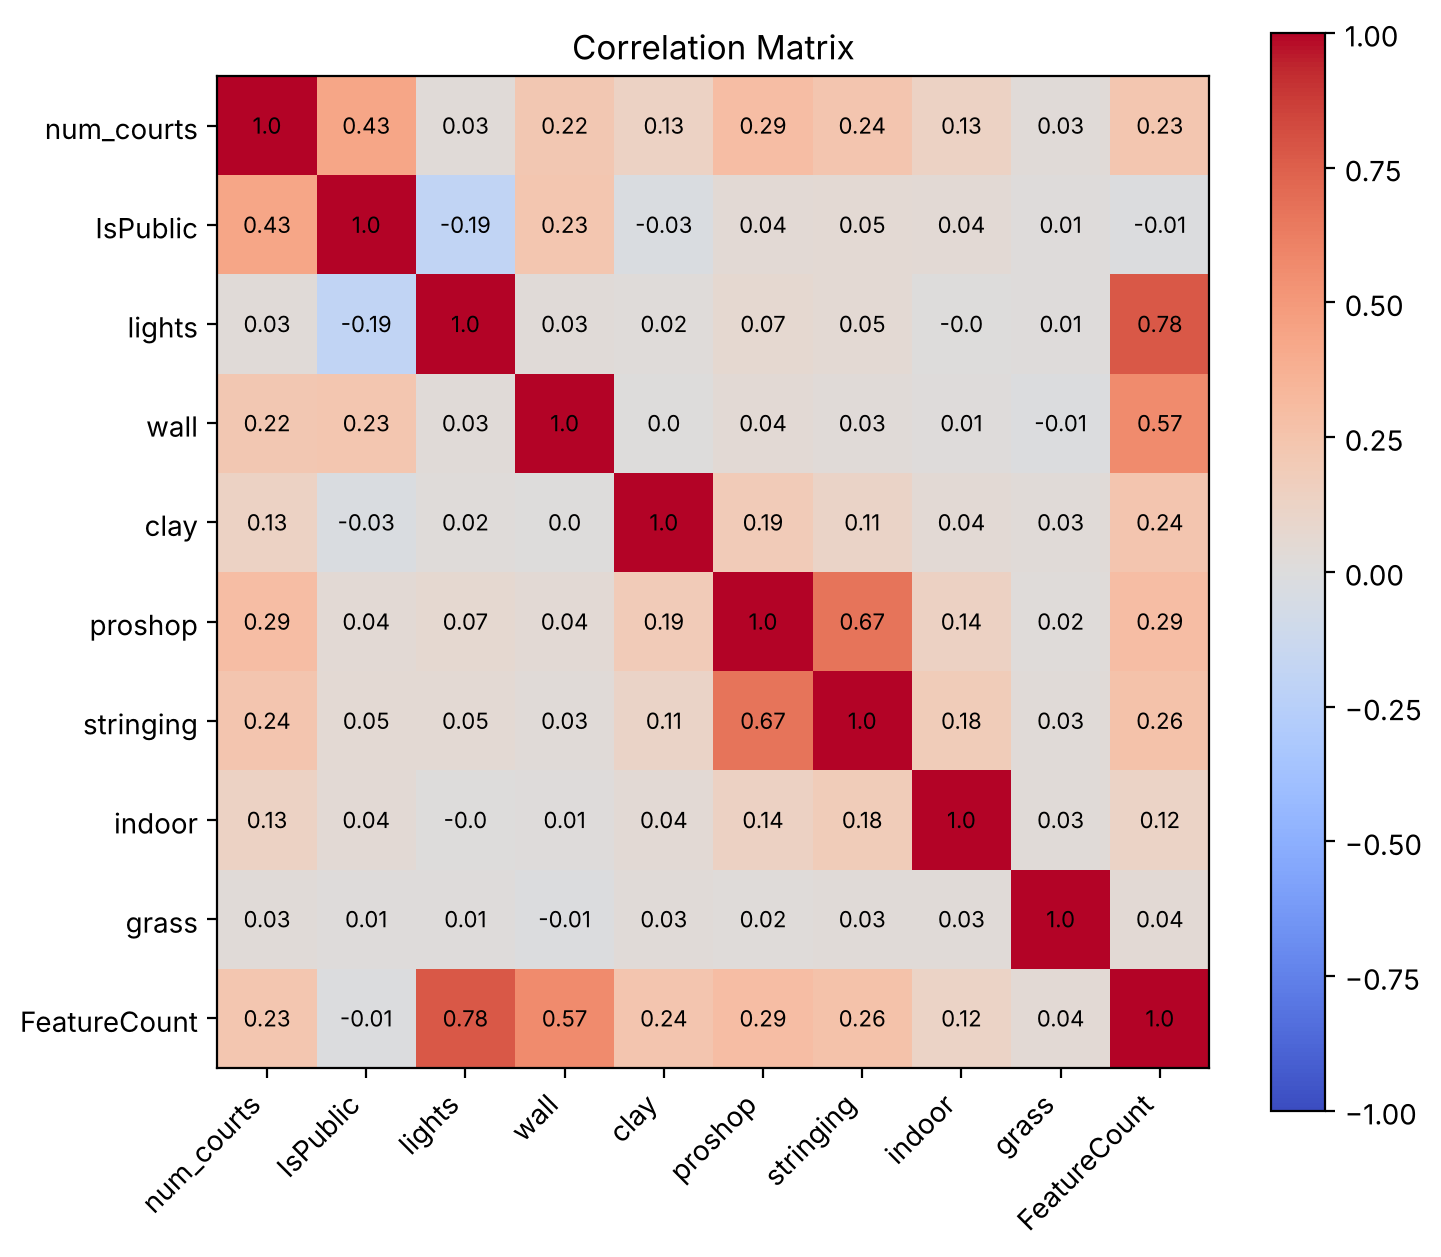

In [24]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.values[i, j], ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im)
ax.set_title("Correlation Matrix")
plt.show()

### Viz 8 — Map of Facilities (Longitude vs Latitude)

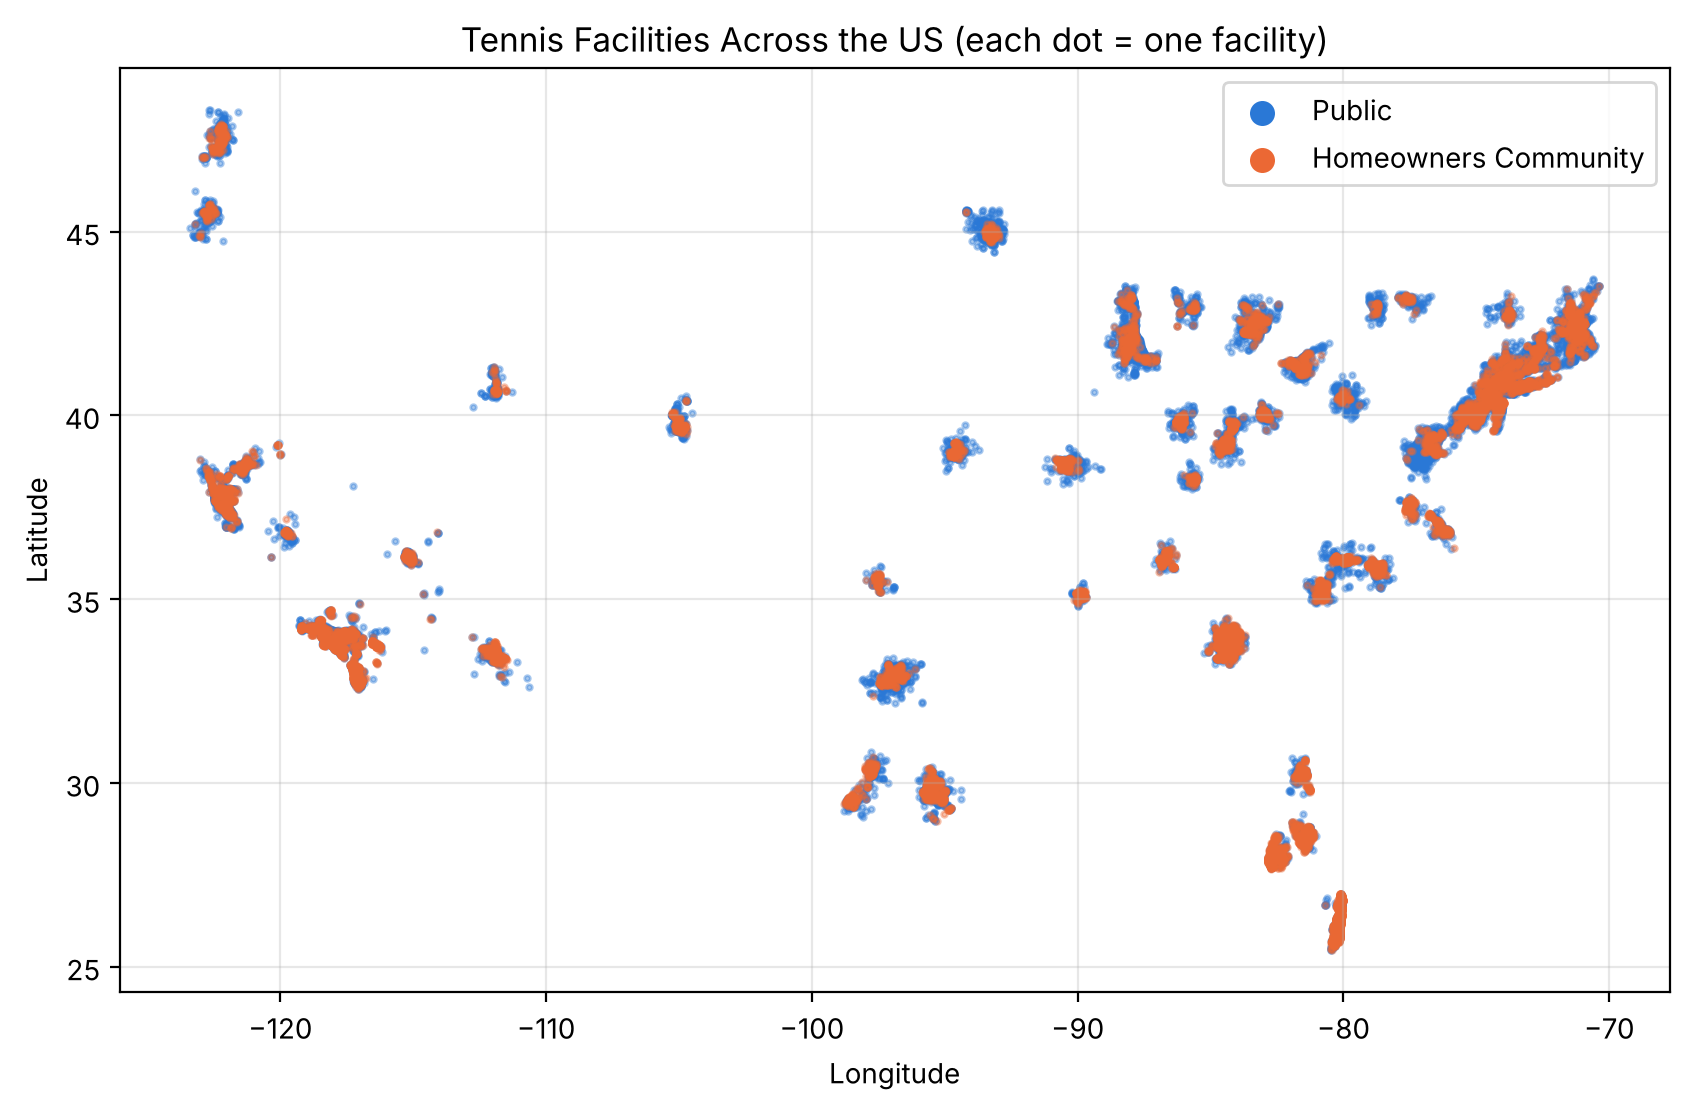

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
for owner, color in [("Public", "#2a78d6"), ("Homeowners Community", "#eb6834")]:
    sub = df_clean[df_clean.ownership_type == owner]
    ax.scatter(sub["longitude"], sub["latitude"], s=4, alpha=0.4, color=color, label=owner)
ax.set_title("Tennis Facilities Across the US (each dot = one facility)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
leg = ax.legend(markerscale=4)
for h in leg.legend_handles:
    h.set_alpha(1)
plt.show()

## 9) Anomaly Detection

In [26]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s < lo) | (s > hi)], lo, hi

for col in ["num_courts", "FeatureCount"]:
    out, lo, hi = iqr_outliers(df_clean[col])
    print(f"{col}: {len(out)} outliers ({len(out)/len(df_clean):.1%}) | bounds = [{lo:.2f}, {hi:.2f}]")

# Coordinates outside the continental US
outside = ~(df_clean["latitude"].between(24, 50) & df_clean["longitude"].between(-125, -66))
print("Coordinates outside the continental US:", outside.sum())

print()
df_clean.nlargest(10, "num_courts")[["facility_name", "metro_area", "state", "ownership_type", "num_courts", "lights", "proshop"]]

num_courts: 2149 outliers (7.2%) | bounds = [-1.00, 7.00]
FeatureCount: 189 outliers (0.6%) | bounds = [-1.50, 2.50]
Coordinates outside the continental US: 0



,facility_name,metro_area,state,ownership_type,num_courts,lights,proshop
9060,Steinbrenner Drive,Tampa-St. Petersburg-Clearwater,FL,Public,41,True,True
7427,West Street,Austin-San Marcos,TX,Public,40,True,False
24920,Corrigan Drive,Pittsburgh,PA,Public,33,True,False
26799,Kuser Road,New York,NY,Public,32,True,False
3814,East Street,Indianapolis,IN,Public,30,False,False
6156,Street Transverse,New York,NY,Public,30,False,False
16495,West Broward Boulevard,Miami-Fort Lauderdale,FL,Public,28,True,True
493,Saint Andrews Boulevard,West Palm Beach - Boca Raton,FL,Public,26,True,True
4182,Unnamed Road,New York,NY,Public,26,True,True
9394,South Gessner Road,Houston - Galveston - Brazoria,TX,Public,26,True,True


## 10) Insights and Recommendations

### Key Insights
1. **Public facilities are the big ones.** They are 54.2% of all facilities but hold 72.0% of all courts (3.99 courts on average vs 1.84 for homeowners communities).
2. **Most facilities are small.** The median facility has 2 courts and 64.4% have only 1–2 courts. The distribution is strongly right-skewed (skew = 2.84).
3. **Large facilities are almost all public.** Of the 5,099 facilities with 5+ courts, 93.6% are public; among the 894 facilities with 9+ courts, 96.2% are public.
4. **Lights are the only widespread feature** (45.9% of facilities) and are more common at homeowners communities (55.9%) than at public facilities (37.4%). 45.2% of facilities have none of the seven features.
5. **Practice walls, pro shops and stringing go with size.** A practice wall exists at 38.9% of 9+ court facilities vs 5.0% of single-court facilities, and pro shops appear at 12.1% of 9+ court facilities vs almost none at 1–2 court facilities. Pro shop and stringing service are strongly linked (r = 0.67).
6. **Rare surfaces and indoor courts:** clay is 1.6% of facilities (mostly Florida and New York), indoor courts 0.3% and grass courts only 10 facilities.
7. **Geography is concentrated.** California (3,864), Florida (3,811) and New York (3,164) hold 36.2% of facilities, and the top 5 states hold 52.6%. New York has more courts than Florida (10,374 vs 9,411) because its facilities are bigger.
8. **Ownership mix differs sharply by place.** D.C. (98.8% public), Minnesota (88.0%) and Illinois (81.2%) are mostly public, while Georgia (18.2%) and Florida (24.5%) rely mostly on homeowners-community courts.
9. **Number of courts is most correlated with public ownership** (r = 0.43), then pro shop (0.29) and stringing service (0.24). Lights are almost unrelated to size (0.03) and slightly negative with public ownership (−0.19).
10. **Anomalies:** 2,149 facilities (7.2%) are IQR outliers above 7 courts, but they are real large complexes (maximum 41 courts, public, Tampa area), so they were kept. No coordinates fall outside the continental US.

### Data Quality Notes
- The CSV header was shifted by one position; the columns were renamed and checked against the attribute blob stored in each row (100% match).
- 4 duplicate rows and 1 facility with 0 courts (a null stored as zero) were removed; ZIP codes were restored to 5-digit text.
- Condition ratings (`quality`) exist for only 285 facilities (1.0%), so quality cannot be analysed reliably.
- The data covers 30 states and 54 metro areas, so state totals are not national totals.

### Recommendations
- **Public access planning:** large public complexes provide most of the playing capacity, so metro areas with a low public share (Atlanta 18.2%, West Palm Beach–Boca Raton 15.7%, Orlando 20.5%) are the first places to study public-court access.
- **Per-capita analysis:** join population or income data to measure courts per 100,000 residents by state and metro area.
- **Data quality:** fix the header at the source and collect condition ratings and amenity data more completely (indoor courts and practice walls look under-recorded).
- **Outlier handling:** `num_courts` is highly skewed (kurtosis = 15.26); apply a log transform or capping before building any model.
- **Predictive modeling:** useful features are `IsPublic`, `num_courts`/`SizeGroup`, `state` and `FeatureCount`.
- **Next step:** train a Logistic Regression or Decision Tree to predict whether a facility is public or has lights, and measure its accuracy.